# 04 · The root locus

Evans' root locus draws the closed-loop poles of 1 + K G(s) = 0 as the gain K runs from 0 to ∞: a picture of
everything a proportional gain can do. The poles start at the open-loop poles, end at the open-loop zeros (or
at infinity along asymptotes), stay on the real axis to the left of an odd number of real poles and zeros, and
leave it at breakaway points where dK/ds = 0. The rules let one sketch the locus by hand; the computation
confirms the sketch; and reading the locus against the damping-ratio lines of notebook 01 is the design method.

**What you will learn**
- apply the root-locus rules: asymptotes, real-axis segments, breakaway points, departure angles
- read gains for a damping ratio and the stability limit from the locus
- anticipate how added poles and zeros reshape the locus
- relate the locus to Routh and to the gain margin

**Before you start:** notebooks 01 and 03  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, stability as st, polynomials as pl, response as rs, frequency as fr
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The locus and its rules

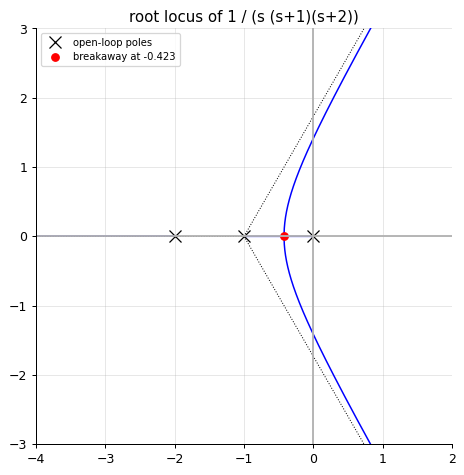

asymptotes from the centroid -1.0 at [ 60. 180. 300.] degrees; real-axis segments [(-1.0, 0.0), (-inf, -2.0)]
breakaway where dK/ds = 0: s = -0.4226 = -1 + 1/sqrt(3)


In [2]:
G = sy.tf([1.0], pl.from_roots([0, -1, -2]))
rl = st.root_locus(G, np.logspace(-2, 2, 800))
fig, ax = plt.subplots(figsize=(6, 6))
for k in range(rl["branches"].shape[1]):
    ax.plot(rl["branches"][:, k].real, rl["branches"][:, k].imag, "b-", lw=1.2)
ax.plot(rl["poles"].real, rl["poles"].imag, "kx", ms=9, label="open-loop poles")
for ang in rl["asymptote_angles"]:
    ax.plot([rl["centroid"], rl["centroid"] + 6 * np.cos(np.radians(ang))], [0, 6 * np.sin(np.radians(ang))], "k:", lw=0.8)
ax.plot(rl["breakaway"], 0 * rl["breakaway"], "ro", label=f"breakaway at {rl['breakaway'][0]:.3f}")
ax.axhline(0, color="0.7"); ax.axvline(0, color="0.7"); ax.set_xlim(-4, 2); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.legend(fontsize=8); ax.set_title("root locus of 1 / (s (s+1)(s+2))"); plt.show()
print(f"asymptotes from the centroid {rl['centroid']:.1f} at {rl['asymptote_angles']} degrees; real-axis segments {[(float(round(a, 2)), float(round(b, 2))) for a, b in rl['real_axis_segments']]}")
print(f"breakaway where dK/ds = 0: s = {rl['breakaway'][0]:.4f} = -1 + 1/sqrt(3)")

Three poles and no zeros: three branches, all going to infinity along asymptotes at 60°, 180° and 300° from
the centroid (0 − 1 − 2)/3 = −1. The real axis between 0 and −1 and to the left of −2 belongs to the locus
(an odd number of real poles to the right); the two branches starting at 0 and −1 meet at the breakaway point
−1 + 1/√3 = −0.423 (where N′D − ND′ = 0) and leave the axis as a complex pair that crosses into the right
half-plane. Every feature is computable from the rules before plotting a point.

## Reading the locus: gain for a damping ratio, and the stability limit

damping ratio 0.5 is reached at K = 1.039, poles (-0.333+0.578j) (and its conjugate); the third pole is at -2.334
the locus crosses the imaginary axis at K = 6.0 (Routh's limit), poles [-3.+0.j     0.+1.414j  0.-1.414j]


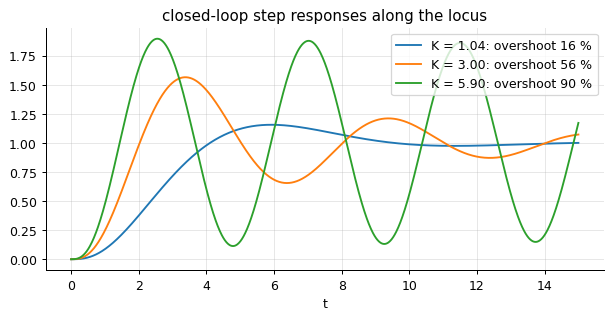

In [3]:
K_half, p_half = st.gain_for_damping(G, 0.5, np.logspace(-2, 1, 3000))
print(f"damping ratio 0.5 is reached at K = {K_half:.3f}, poles {np.round(p_half, 3)} (and its conjugate); the third pole is at {np.round(pl.roots(pl.add(G.den, K_half * G.num)).real.min(), 3)}")
K_marg = 6.0
print(f"the locus crosses the imaginary axis at K = {K_marg} (Routh's limit), poles {np.round(pl.roots(pl.add(G.den, K_marg * G.num)), 3)}")
fig, ax = plt.subplots(figsize=(8, 3.5))
for K in (K_half, 3.0, 5.9):
    T = sy.feedback(sy.tf(K * G.num, G.den))
    t, y = rs.step(T, 15.0)
    ax.plot(t, y, label=f"K = {K:.2f}: overshoot {rs.step_info(t, y, final=T.dcgain())['overshoot']:.0f} %")
ax.legend(); ax.set_xlabel("t"); ax.set_title("closed-loop step responses along the locus"); plt.show()

Design on the locus is reading it against specifications: the gain at which the complex branch crosses the
ζ = 0.5 line (K ≈ 1.04) gives about 16 % overshoot, but the third pole at −2.3 is not far enough to be ignored
(the actual overshoot is higher than the second-order formula's); at K = 6 the pair sits on the imaginary axis
and the loop oscillates. The locus also shows the structural fact that no gain can fix: a plant with three
poles and no zeros always goes unstable at high gain.

## Compensators change the locus

plant alone                 : centroid -1.00, asymptotes [ 60. 180. 300.], gain for zeta = 0.5: 1.04


with lead (s + 1)/(s + 10)  : centroid -4.00, asymptotes [ 60. 180. 300.], gain for zeta = 0.5: 28.74


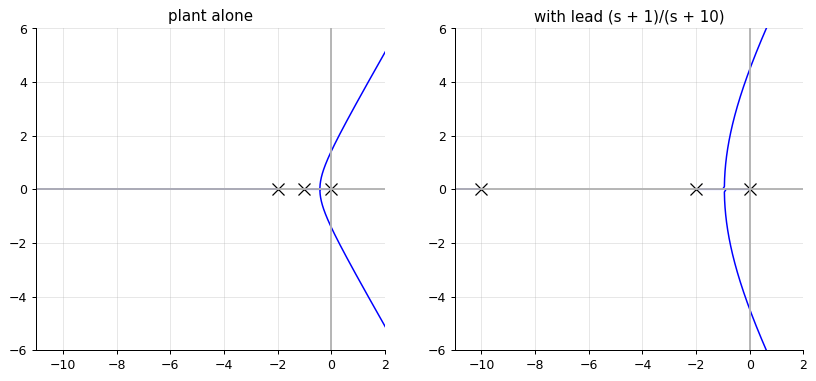

In [4]:
Glead = sy.series(sy.tf([1.0, 1.0], [1.0, 10.0]), G)              # lead: zero at -1 cancels... no: adds zero at -1, pole at -10
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, g) in zip(axes, (("plant alone", G), ("with lead (s + 1)/(s + 10)", Glead))):
    r = st.root_locus(g, np.logspace(-2, 3, 800))
    for k in range(r["branches"].shape[1]):
        ax.plot(r["branches"][:, k].real, r["branches"][:, k].imag, "b-", lw=1.2)
    ax.plot(r["poles"].real, r["poles"].imag, "kx", ms=9); ax.plot(r["zeros"].real, r["zeros"].imag, "ko", ms=8, mfc="none")
    ax.axhline(0, color="0.7"); ax.axvline(0, color="0.7"); ax.set_xlim(-11, 2); ax.set_ylim(-6, 6); ax.set_aspect("equal"); ax.set_title(name)
    print(f"{name:<28}: centroid {r['centroid']:.2f}, asymptotes {np.round(r['asymptote_angles'], 0)}, gain for zeta = 0.5: {st.gain_for_damping(g, 0.5, np.logspace(-2, 2, 3000))[0]:.2f}")
plt.show()

Adding a lead compensator's zero and pole moves the centroid left (to −4) and bends the locus away from
the right half-plane: a higher gain now reaches the same damping ratio, so the closed loop is faster with the
same overshoot. (The zero at −1 cancels the plant pole at −1 here - allowed for a stable pole, though the
cancelled mode remains in the disturbance response; cancelling an *unstable* pole is never allowed, as notebook
08 shows.) This is the root-locus view of the frequency-domain lead design of notebook 07.

## Departure angles and complex poles

departure angles from the complex poles: {(-1+1j): 63.43}
the angle condition: 180 - (sum of angles from the other poles) = 180 - 90 - atan(1/2) = 63.43 degrees


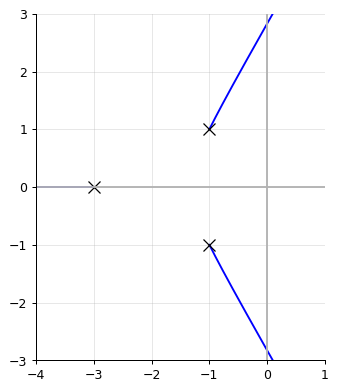

In [5]:
Gc = sy.tf([1.0], pl.from_roots([-1 + 1j, -1 - 1j, -3.0]))
r = st.root_locus(Gc, np.logspace(-2, 2, 600))
print("departure angles from the complex poles:", {k: round(float(v), 2) for k, v in r["departure_angles"].items()})
print("the angle condition: 180 - (sum of angles from the other poles) = 180 - 90 - atan(1/2) =", round(180 - 90 - np.degrees(np.arctan(0.5)), 2), "degrees")
fig, ax = plt.subplots(figsize=(5, 5))
for k in range(3):
    ax.plot(r["branches"][:, k].real, r["branches"][:, k].imag, "b-")
ax.plot(r["poles"].real, r["poles"].imag, "kx", ms=9); ax.axhline(0, color="0.7"); ax.axvline(0, color="0.7"); ax.set_xlim(-4, 1); ax.set_ylim(-3, 3); ax.set_aspect("equal"); plt.show()

The angle condition, ∠G(s) = 180° on the locus, fixes the direction in which a branch leaves a complex pole;
here 63.4°, pointing up and to the right - towards instability. The rules are a complete algorithm: a reader
who can compute angles can draw the locus of any transfer function, which is the real reason the method
survives in an age when the roots can be computed in a millisecond.

## Inside the algorithm: the breakaway point from dK/ds = 0

In [6]:
N, D = G.num, G.den
dK = pl.sub(pl.mul(pl.derivative(N), D), pl.mul(N, pl.derivative(D)))      # d/ds (D/N) = 0  <=>  N' D - N D' = 0
cand = pl.roots(dK)
Kc = -pl.evaluate(D, cand) / pl.evaluate(N, cand)
print("candidates:", np.round(cand, 4), " gains:", np.round(Kc.real, 4), "-> the one with K > 0 on a locus segment is the breakaway point")

candidates: [-1.5774 -0.4226]  gains: [-0.3849  0.3849] -> the one with K > 0 on a locus segment is the breakaway point


## Exercises
1. Draw the root locus of 1/(s (s + 4)(s^2 + 4s + 20)) by the rules first (asymptotes, breakaway, departure angles), then compute it. At what gain does it cross the imaginary axis, and does Routh agree?
2. Add a zero to 1/(s (s + 1)(s + 2)) at -0.5, -1.5 and -3 in turn and describe how the locus and the maximum achievable damping change. Which position is best for a fast, well-damped loop?
3. **Implement it yourself:** compute a root locus by solving D(s) + K N(s) = 0 for 500 gains and matching each root to the nearest root at the previous gain (so that branches are continuous); plot it against `stability.root_locus`.